In [1]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


#Filter for Data Analyst roles 
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()


Text(0, 0.5, 'Count')

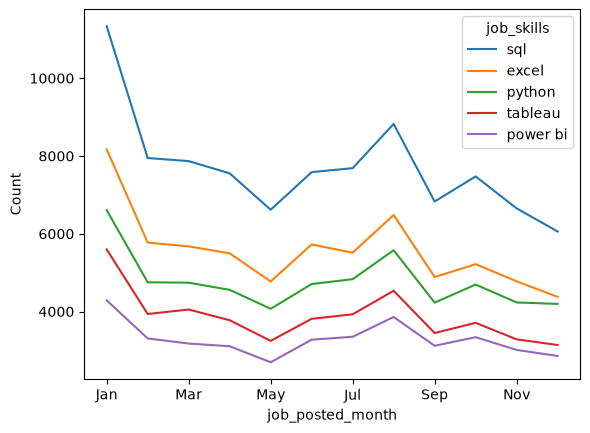

In [20]:
df_DA['job_posted_month_no'] = df_DA['job_posted_date'].dt.month

df_DA_explode = df_DA.explode('job_skills')
df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no',columns='job_skills',aggfunc ='size',fill_value = 0)

df_DA_pivot.loc['Total'] = df_DA_pivot.sum()
df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['Total'].sort_values(ascending=False).index]
df_DA_pivot = df_DA_pivot.drop('Total')

df_DA_pivot = df_DA_pivot.reset_index()
df_DA_pivot['job_posted_month'] = df_DA_pivot['job_posted_month_no'].apply(
    lambda x: pd.to_datetime(x, format='%m').strftime('%b')
)
df_DA_pivot= df_DA_pivot.set_index('job_posted_month')
df_DA_pivot= df_DA_pivot.drop(columns='job_posted_month_no')

#Get the top 5 skills
df_DA_pivot.iloc[:,:5].plot(kind='line')
plt.ylabel('Count')

Text(0, 0.5, 'Count')

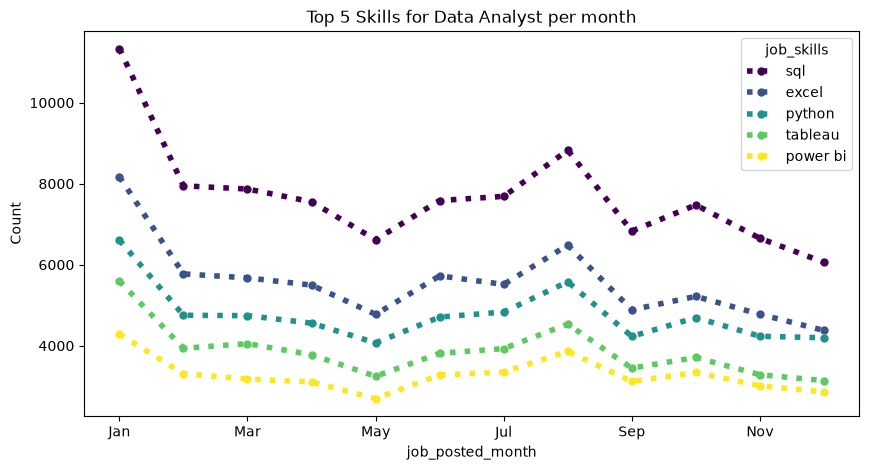

In [35]:
df_DA_pivot.iloc[:,:5].plot(
    kind='line',
    linewidth =  4,
    linestyle = ':',
    colormap = 'viridis',
    marker = 'o',
    markersize = 5,
    figsize=(10,5),
    title = 'Top 5 Skills for Data Analyst per month'
)
plt.ylabel('Count')